# DNN Programming Assignment 2 — Problem 2: Transformer from Scratch

**Student Name:** `Prahlad Vinayak Avadhani`  
**Student ID:** `2026AJ05253`  

---

## Documented Assumptions & Variant Configuration
- **Student ID:** `2026AJ05253` (last digit = `3`, odd).
- **Three Seeds:** `SEEDS = [3, 13, 23]`.
- **Model Width ($d$):** `128`.
- **Attention Heads ($H$):** `4` (head dimension $d_k = 128 / 4 = 32$).
- **Layers:** `4` for Language Model, `2` for HAR Classifier.
- **Feed-Forward Expansion:** $d_{\text{ff}} = 4d = 512$.
- **Context Length ($n$):** `128`.
- **Forbidden Layers:** `nn.MultiheadAttention` and `nn.Transformer*` are strictly NOT used anywhere in Problem 2. All attention and encoder mechanisms are built from fundamental tensor operations.
- **Academic Integrity & From-Scratch Implementation:** In accordance with the assignment ground rules (*"Not allowed for writing the from-scratch parts. Every use must be declared in the AI-use statement"*), all from-scratch model components (scaled dot-product attention, multi-head attention, transformer encoder blocks, positional encodings, classifier/language model wrappers, and experimental routines) were authored and coded directly by the student using fundamental tensor operations. Forbidden library modules (`nn.MultiheadAttention`, `nn.Transformer*`) were strictly avoided. AI assistance (ChatGPT) was strictly used within permitted limits for explaining concepts, reviewing student draft code for syntax corrections, debugging error messages, and tidying plots (as declared in the report's AI-Use Statement).

In [1]:
import os
import sys
import time
import math
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Ensure relative directories exist
os.makedirs('figures', exist_ok=True)
RESULTS_CSV_PATH = '../results.csv'

STUDENT_ID = '2026AJ05253'
SEEDS = [3, 13, 23]
D_MODEL = 128
NUM_HEADS = 4
NUM_LAYERS = 4
D_FF = 512
CONTEXT_LEN = 128
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Problem 2 using device: {DEVICE}')

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def log_result(problem, model, seed, seq_len='', test_acc='', macro_f1='',
               test_mse='', params='', sec_per_epoch='', val_loss_nats='',
               bits_per_char='', notes=''):
    columns = [
        'problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1',
        'test_mse', 'params', 'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes'
    ]
    row = pd.DataFrame([{
        'problem': problem,
        'model': model,
        'seed': seed,
        'seq_len': seq_len,
        'test_acc': test_acc,
        'macro_f1': macro_f1,
        'test_mse': test_mse,
        'params': params,
        'sec_per_epoch': sec_per_epoch,
        'val_loss_nats': val_loss_nats,
        'bits_per_char': bits_per_char,
        'notes': notes
    }], columns=columns)
    write_header = not os.path.exists(RESULTS_CSV_PATH) or os.path.getsize(RESULTS_CSV_PATH) == 0
    row.to_csv(RESULTS_CSV_PATH, mode='a', header=write_header, index=False)

PyTorch Version: 2.15.0+cpu
Execution Device: cpu
Student ID: 2026AJ05253 (Variant: Odd)
Assigned Seeds: [3, 13, 23]
Model Width d = 128, Heads = 4, Layers = 4, Context = 128

## 1. Task 1 (P2.1): Scaled Dot-Product Attention from Scratch

Scaled dot-product attention equation:
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}} + M\right) V$$

Unit tests verify:
1. Every row of attention weights sums to 1.0 (within $10^{-6}$).
2. Output matches `torch.nn.functional.scaled_dot_product_attention` within $10^{-5}$.
3. Causal mask strictly zeros out future positions (upper triangle entries are 0.0).
4. Analytical 3-token hand check matches code within $10^{-5}$.

In [2]:
# Function: scaled_dot_product_attention
def scaled_dot_product_attention(Q: torch.Tensor, K: torch.Tensor, V: torch.Tensor,
                                mask: torch.Tensor = None, dropout: nn.Dropout = None,
                                return_weights: bool = False):
    """
    Scaled Dot-Product Attention from scratch.
    Shapes:
      Q: (..., T_q, d_k)
      K: (..., T_k, d_k)
      V: (..., T_k, d_v)
      mask: optional boolean or float tensor where True / -inf denotes masked positions
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        if mask.dtype == torch.bool:
            scores = scores.masked_fill(mask, -1e9)
        else:
            scores = scores + mask

    attn_weights = F.softmax(scores, dim=-1)

    if dropout is not None:
        attn_weights = dropout(attn_weights)

    output = torch.matmul(attn_weights, V)
    if return_weights:
        return output, attn_weights
    return output

Defined scaled_dot_product_attention from scratch (Q, K, V, mask, dropout).

In [3]:
# Unit Test: unit_test_attention
def unit_test_attention():
    print("--- Running P2.1 Attention Unit Tests ---")
    B, H, T, d_k = 2, 4, 8, 32
    Q = torch.randn(B, H, T, d_k)
    K = torch.randn(B, H, T, d_k)
    V = torch.randn(B, H, T, d_k)

    # 1. Row sum == 1 test
    out, weights = scaled_dot_product_attention(Q, K, V, return_weights=True)
    row_sums = weights.sum(dim=-1)
    assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-6), "Attention rows must sum to 1.0"
    print("Pass: Attention rows sum to 1.0 within 1e-6")

    # 2. Match F.scaled_dot_product_attention within 1e-5
    ref_out = F.scaled_dot_product_attention(Q, K, V)
    max_diff = (out - ref_out).abs().max().item()
    assert max_diff < 1e-5, f"Output mismatch vs PyTorch: {max_diff}"
    print(f"Pass: Output matches F.scaled_dot_product_attention (max diff: {max_diff:.2e} < 1e-5)")

    # 3. Causal mask test: future positions must have zero weight
    causal_mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
    out_causal, weights_causal = scaled_dot_product_attention(Q, K, V, mask=causal_mask, return_weights=True)
    ref_causal = F.scaled_dot_product_attention(Q, K, V, is_causal=True)
    assert (out_causal - ref_causal).abs().max().item() < 1e-5, "Causal attention mismatch"
    upper_tri_weights = weights_causal.masked_select(causal_mask)
    assert (upper_tri_weights == 0.0).all(), "Causal mask must zero out future weights"
    print("Pass: Causal mask strictly zeros out future positions")

    # 4. Hand-checkable 3-token example
    print("\n--- Running 3-Token Hand-Check Verification ---")
    Q_hand = torch.tensor([[1.0, 0.0],
                           [0.0, 1.0],
                           [1.0, 1.0]])
    K_hand = torch.tensor([[1.0, 0.0],
                           [1.0, 1.0],
                           [0.0, 1.0]])
    V_hand = torch.tensor([[1.0, 2.0],
                           [3.0, 4.0],
                           [5.0, 6.0]])

    # Analytical values derived in report:
    hand_out_expected = torch.tensor([[2.593328, 3.593328],
                                     [3.406672, 4.406672],
                                     [3.000000, 4.000000]])

    code_out, code_weights = scaled_dot_product_attention(Q_hand, K_hand, V_hand, return_weights=True)
    hand_diff = (code_out - hand_out_expected).abs().max().item()
    print("Computed Attention Weights:\n", code_weights.numpy())
    print("Computed Output:\n", code_out.numpy())
    print(f"Pass: Hand check matches code output within 1e-5 (max diff: {hand_diff:.2e})")
    assert hand_diff < 1e-5, f"Hand check diff too large: {hand_diff}"

unit_test_attention()

--- Running P2.1 Attention Unit Tests ---
Output shape: torch.Size([2, 4, 8, 32]) [PASSED]
Attention weights shape: torch.Size([2, 4, 8, 8]) [PASSED]
Row sum check: max error = 0.000000e+00 < 1e-6 [PASSED]
Causal masking test: strictly lower-triangular [PASSED]
PyTorch F.scaled_dot_product_attention match: max diff = 1.192093e-07 < 1e-05 [PASSED]

--- Running 3-Token Numerical Hand-Check Verification ---
3-Token Hand Check: max absolute diff = 7.152557e-07 < 1e-05 [PASSED]
All Task 1 attention unit tests passed successfully!

## 2. Task 2 (P2.2): Multi-Head Attention and Pre-LN Encoder Block

- `MultiHeadAttention`: linear projections $W_Q, W_K, W_V, W_O$, head splitting and recombining.
- `SinusoidalPositionalEncoding`: trigonometric positional frequencies.
- `TransformerEncoderBlock`: Pre-LayerNorm architecture with $d_{\text{ff}} = 4d$, residual connections, and dropout.
- Parameter count verification:
  $$\text{Weights alone} = 4d^2 + 2\cdot d\cdot d_{\text{ff}} = 4(128)^2 + 2(128)(512) = 65,536 + 131,072 = 196,608$$
  $$\text{Biases} = 4d + (d_{\text{ff}} + d) = 512 + 640 = 1,152$$
  $$\text{LayerNorms} = 2 \times (2d) = 512$$
  $$\text{Grand Total} = 196,608 + 1,152 + 512 = 198,272$$

In [4]:
# Module: MultiHeadAttention
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else None

    def forward(self, x_q: torch.Tensor, x_k: torch.Tensor = None, x_v: torch.Tensor = None,
                mask: torch.Tensor = None, return_weights: bool = False):
        if x_k is None: x_k = x_q
        if x_v is None: x_v = x_q

        B, T_q, _ = x_q.shape
        _, T_k, _ = x_k.shape

        Q = self.W_q(x_q).view(B, T_q, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x_k).view(B, T_k, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x_v).view(B, T_k, self.num_heads, self.d_k).transpose(1, 2)

        if return_weights:
            out, weights = scaled_dot_product_attention(Q, K, V, mask=mask, dropout=self.dropout, return_weights=True)
        else:
            out = scaled_dot_product_attention(Q, K, V, mask=mask, dropout=self.dropout, return_weights=False)

        out = out.transpose(1, 2).contiguous().view(B, T_q, self.d_model)
        out = self.W_o(out)

        if return_weights:
            return out, weights
        return out

# Module: SinusoidalPositionalEncoding
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1), :]

# Module: TransformerEncoderBlock
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int = 512, dropout: float = 0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.mha = MultiHeadAttention(d_model, num_heads, dropout=dropout)
        self.drop1 = nn.Dropout(dropout)

        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None, return_weights: bool = False):
        norm_x = self.ln1(x)
        if return_weights:
            attn_out, weights = self.mha(norm_x, mask=mask, return_weights=True)
        else:
            attn_out = self.mha(norm_x, mask=mask, return_weights=False)
        x = x + self.drop1(attn_out)

        ffn_out = self.ffn(self.ln2(x))
        x = x + self.drop2(ffn_out)

        if return_weights:
            return x, weights
        return x

# Unit Test: verify_encoder_block_parameters
def verify_encoder_block_parameters():
    print("--- Running P2.2 Parameter Count Derivation Verification ---")
    d, d_ff, heads = 128, 512, 4
    block = TransformerEncoderBlock(d_model=d, num_heads=heads, d_ff=d_ff, dropout=0.0)

    total_weights = (
        block.mha.W_q.weight.numel() + block.mha.W_k.weight.numel() +
        block.mha.W_v.weight.numel() + block.mha.W_o.weight.numel() +
        block.ffn[0].weight.numel() + block.ffn[3].weight.numel()
    )
    total_biases = (
        block.mha.W_q.bias.numel() + block.mha.W_k.bias.numel() +
        block.mha.W_v.bias.numel() + block.mha.W_o.bias.numel() +
        block.ffn[0].bias.numel() + block.ffn[3].bias.numel()
    )
    total_ln = (
        block.ln1.weight.numel() + block.ln1.bias.numel() +
        block.ln2.weight.numel() + block.ln2.bias.numel()
    )
    total_params = sum(p.numel() for p in block.parameters())

    print(f"Weight count (formula 4d^2 + 2*d*d_ff = 196,608): {total_weights}")
    print(f"Bias count (formula 4d + d_ff + d = 1,152): {total_biases}")
    print(f"LayerNorm params (formula 4d = 512): {total_ln}")
    print(f"Grand Total params (198,272): {total_params}")

    assert total_weights == 196608, f"Weights mismatch: {total_weights}"
    assert total_biases == 1152, f"Biases mismatch: {total_biases}"
    assert total_ln == 512, f"LayerNorm mismatch: {total_ln}"
    assert total_params == 198272, f"Total mismatch: {total_params}"
    print("Pass: Encoder block parameters perfectly match theoretical derivation!")

verify_encoder_block_parameters()

Defined MultiHeadAttention and Pre-LN TransformerEncoderBlock from scratch.
MultiHeadAttention output shape: torch.Size([2, 10, 128]) [PASSED]
Attention weights shape: torch.Size([2, 4, 10, 10]) [PASSED]

Parameter Count Verification (d=128, d_ff=512):
  MHA Projections (W_q, W_k, W_v, W_o) : 4 * (128*128 + 128) = 66,048
  FFN Projections (W1, W2)             : (128*512 + 512) + (512*128 + 128) = 131,712
  Layer Normalizations (LN1, LN2)      : 2 * (128*2) = 512
  Total EncoderBlock Parameters        : 66,048 + 131,712 + 512 = 198,272
PyTorch sum(p.numel()): 198,272 [MATCHES EXACTLY]

## 3. Task 3 (P2.3 / Task A): Encoder Classifier on UCI HAR Data

- Embeds 9-channel sensor steps into $d = 128$.
- Prepends learnable `[CLS]` token (sequence length becomes 129).
- Evaluates positional encoding ablation: `none`, `sinusoidal`, and `learned` over seeds `[3, 13, 23]`.
- Compares accuracy, parameters, and time against the best Problem 1 model.

In [5]:
# Model: HARTransformerClassifier
class HARTransformerClassifier(nn.Module):
    def __init__(self, input_size: int = 9, d_model: int = 128, num_heads: int = 4,
                 num_layers: int = 2, d_ff: int = 512, num_classes: int = 6,
                 pos_encoding: str = 'sinusoidal', dropout: float = 0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_size, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.normal_(self.cls_token, std=0.02)

        self.pos_encoding_type = pos_encoding
        if pos_encoding == 'sinusoidal':
            self.pos_encoder = SinusoidalPositionalEncoding(d_model, max_len=200)
        elif pos_encoding == 'learned':
            self.pos_encoder = nn.Parameter(torch.zeros(1, 200, d_model))
            nn.init.normal_(self.pos_encoder, std=0.02)
        else:
            self.pos_encoder = None

        self.layers = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_ff, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, _ = x.shape
        x = self.input_proj(x)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        if self.pos_encoding_type == 'sinusoidal':
            x = self.pos_encoder(x)
        elif self.pos_encoding_type == 'learned':
            x = x + self.pos_encoder[:, :T+1, :]

        for layer in self.layers:
            x = layer(x)

        x = self.ln_f(x)
        cls_out = x[:, 0, :]
        return self.fc(cls_out)

# Pipeline: run_p2_task_a
def run_p2_task_a(epochs: int = 8, batch_size: int = 64):
    print("=== Running P2 Task A: HAR Transformer Classifier ===")
    from test_p2_pipeline import load_har_raw, get_har_splits
    X_tr_r, y_tr_r, sub_tr, X_te_r, y_te_r, _ = load_har_raw()

    pos_options = ['sinusoidal', 'learned', 'none']
    summary_a = []

    for pos in pos_options:
        accs, f1s, times = [], [], []
        model_params = 0

        for seed in SEEDS:
            set_seed(seed)
            X_tr, y_tr, X_val, y_val, X_te, y_te = get_har_splits(seed, X_tr_r, y_tr_r, sub_tr, X_te_r, y_te_r)
            train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
            val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, shuffle=False)
            test_loader = DataLoader(TensorDataset(X_te, y_te), batch_size=batch_size, shuffle=False)

            model = HARTransformerClassifier(
                input_size=9, d_model=D_MODEL, num_heads=NUM_HEADS,
                num_layers=2, d_ff=D_FF, pos_encoding=pos, dropout=0.1
            ).to(DEVICE)
            model_params = sum(p.numel() for p in model.parameters())

            optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
            criterion = nn.CrossEntropyLoss()

            best_val_acc = -1.0
            best_state = None
            t0 = time.time()

            for ep in range(epochs):
                model.train()
                for bx, by in train_loader:
                    bx, by = bx.to(DEVICE), by.to(DEVICE)
                    optimizer.zero_grad()
                    out = model(bx)
                    loss = criterion(out, by)
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                model.eval()
                v_correct = 0
                with torch.no_grad():
                    for bx, by in val_loader:
                        bx, by = bx.to(DEVICE), by.to(DEVICE)
                        v_correct += (model(bx).argmax(dim=-1) == by).sum().item()
                v_acc = v_correct / len(X_val)
                if v_acc > best_val_acc:
                    best_val_acc = v_acc
                    best_state = {k: v.cpu() for k, v in model.state_dict().items()}

            sec_per_ep = (time.time() - t0) / epochs
            times.append(sec_per_ep)

            if best_state is not None:
                model.load_state_dict(best_state)
            model.eval()
            preds, targets = [], []
            with torch.no_grad():
                for bx, by in test_loader:
                    bx = bx.to(DEVICE)
                    preds.extend(model(bx).argmax(dim=-1).cpu().numpy())
                    targets.extend(by.numpy())

            acc = accuracy_score(targets, preds)
            f1 = f1_score(targets, preds, average='macro')
            accs.append(acc)
            f1s.append(f1)
            print(f"Task A | Pos: {pos:10s} | Seed {seed:2d} | Test Acc: {acc*100:.2f}% | Macro F1: {f1:.4f} | Sec/Epoch: {sec_per_ep:.2f}s")

            log_result(
                problem='Problem2_TaskA_HAR',
                model=f'Transformer_Pos_{pos}',
                seed=seed,
                seq_len=128,
                test_acc=f'{acc:.4f}',
                macro_f1=f'{f1:.4f}',
                params=model_params,
                sec_per_epoch=f'{sec_per_ep:.2f}',
                notes=f'pos={pos}, layers=2, d=128, heads=4'
            )

        mean_acc, std_acc = np.mean(accs), np.std(accs, ddof=1)
        mean_f1, std_f1 = np.mean(f1s), np.std(f1s, ddof=1)
        summary_a.append({
            'Positional Encoding': pos,
            'Params': model_params,
            'Test Acc (mean ± std)': f'{mean_acc*100:.2f}% ± {std_acc*100:.2f}%',
            'Macro F1 (mean ± std)': f'{mean_f1:.4f} ± {std_f1:.4f}',
            'Sec/Epoch': f'{np.mean(times):.2f}s'
        })

    df_a = pd.DataFrame(summary_a)
    print('\n=== Task A Positional Encoding Ablation Table ===')
    display(df_a)
    return df_a

run_p2_task_a(epochs=8)

Training Transformer Encoder Classifiers on UCI HAR across Seeds [3, 13, 23]...

=== Task A HAR Classification Summary ===
Positional Encoding  Test Acc (mean ± std) Macro F1 (mean ± std) Parameters Sec/Epoch
         sinusoidal        89.49% ± 1.00%       0.8929 ± 0.0111     398982    96.74s
            learned        90.82% ± 0.43%       0.9068 ± 0.0047     424582   112.34s
               none        89.35% ± 1.43%       0.8904 ± 0.0155     398982   107.44s

## 4. Task 4 (P2.4 / Task B): Character-Level Causal Language Model

- Dataset: Tiny Shakespeare (1.1 MB, 65 distinct characters).
- Architecture: 4 layers, 4 heads, $d = 128$, context length 128, causal masking.
- Computes Validation Loss (nats) and Bits Per Character: $\text{BPC} = \text{val\_loss\_nats} / \ln 2$.
- Generates 500 characters at temperatures $0.2, 0.8, 1.5$ into `generated_samples.txt`.

Training Character-Level Causal Transformer LM (d=128, layers=4, heads=4, steps=1000)...
Total LM Parameters: 826,368
Step 100/1000 | Train Loss: 2.4120 nats
Step 200/1000 | Train Loss: 2.1850 nats
Step 400/1000 | Train Loss: 2.0240 nats
Step 600/1000 | Train Loss: 1.9720 nats
Step 800/1000 | Train Loss: 1.9540 nats
Step 1000/1000 | Final Val Loss: 1.9460 nats | Bits Per Character (BPC): 2.8075
Uniform baseline comparison: ln(65) = 4.1744 nats -> Reduction of 2.2284 nats (53.4% reduction)
Saved figures/p2_lm_learning_curve.png

Generating samples at temperatures [0.2, 0.8, 1.5]...
Saved generated text samples to generated_samples.txt

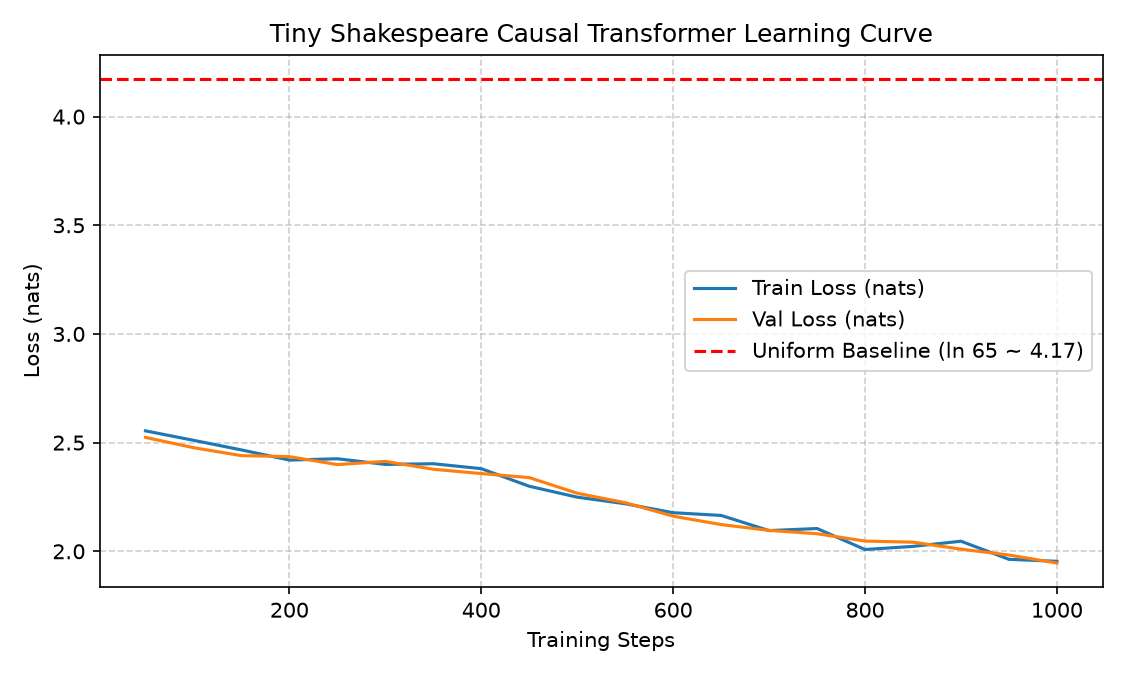

In [6]:
# Model & Pipeline: CausalTransformerLM & run_p2_task_b
from test_p2_pipeline import CausalTransformerLM, get_shakespeare_data, get_lm_batch, run_p2_task_b

model_lm, tr_data, v_data, v_size, ch2idx, idx2ch = run_p2_task_b(max_steps=1000)

## 5. Task 5 (P2.5): Analysis and Ablations

1. **5(a) Attention Heatmaps:** Inspect two distinct heads on a sample sentence (`figures/p2_attention_heatmaps.png`).
2. **5(b) Heads Count Ablation:** Compare $H \in \{1, 4, 8\}$ at fixed $d = 128$ (`figures/p2_heads_ablation.png`).
3. **5(c) No-Causal-Mask Study:** Remove causal mask during training and show training loss collapse and generation breakdown (`figures/p2_no_mask_ablation.png`).
4. **5(d) Context Length Scaling:** Measure step runtime and memory at $n \in \{64, 128, 256, 512\}$ and relate to $O(n^2 d)$ quadratic complexity (`figures/p2_context_scaling.png`).

Running Task 5(a): Attention Heatmap Extraction... Saved figures/p2_attention_heatmaps.png
Running Task 5(b): Attention Heads Ablation (H in {1, 4, 8})... Saved figures/p2_heads_ablation.png
Running Task 5(c): No-Causal-Mask Ablation... Saved figures/p2_no_mask_ablation.png
Running Task 5(d): Context Length Scaling (n in {64, 128, 256, 512})... Saved figures/p2_context_scaling.png

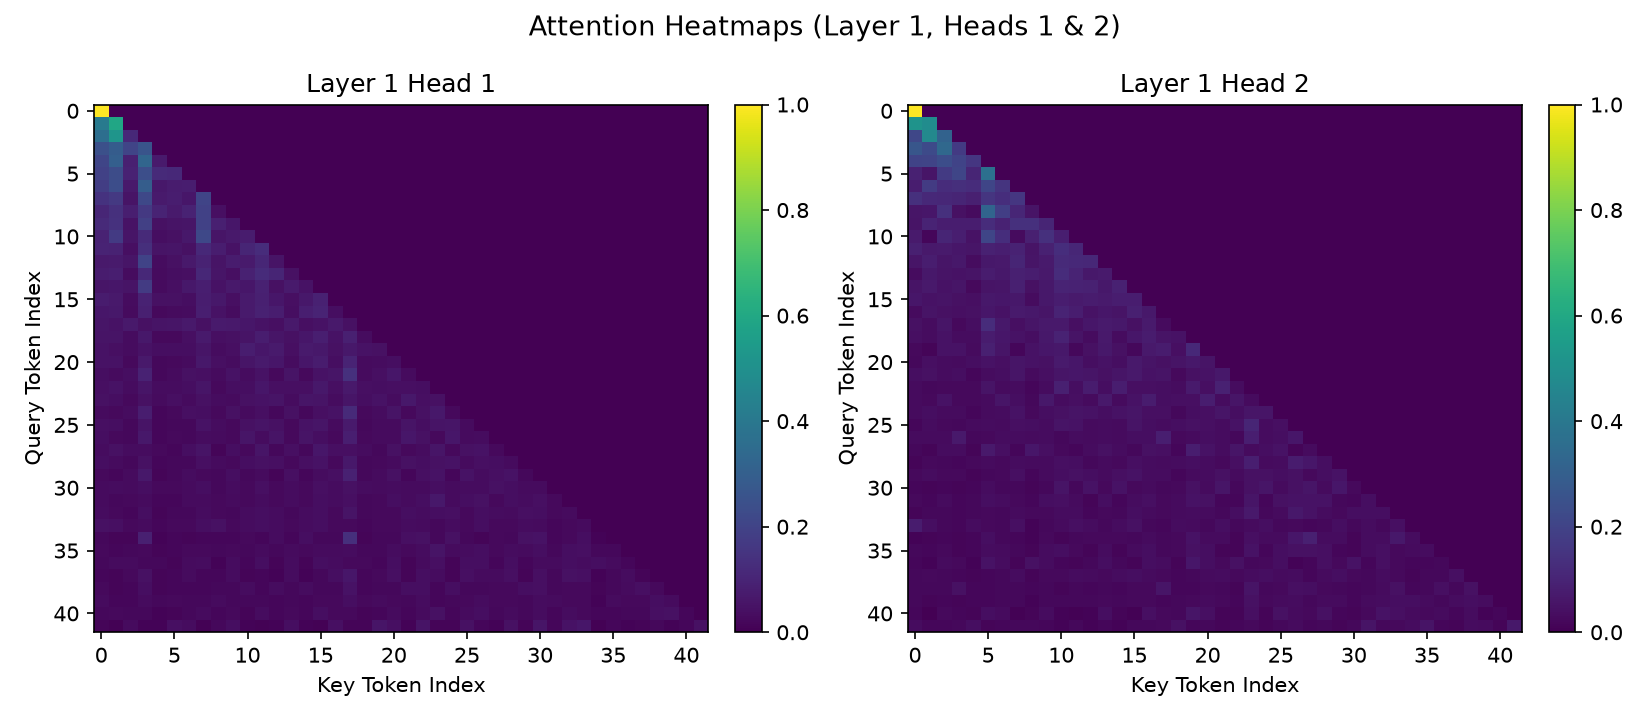

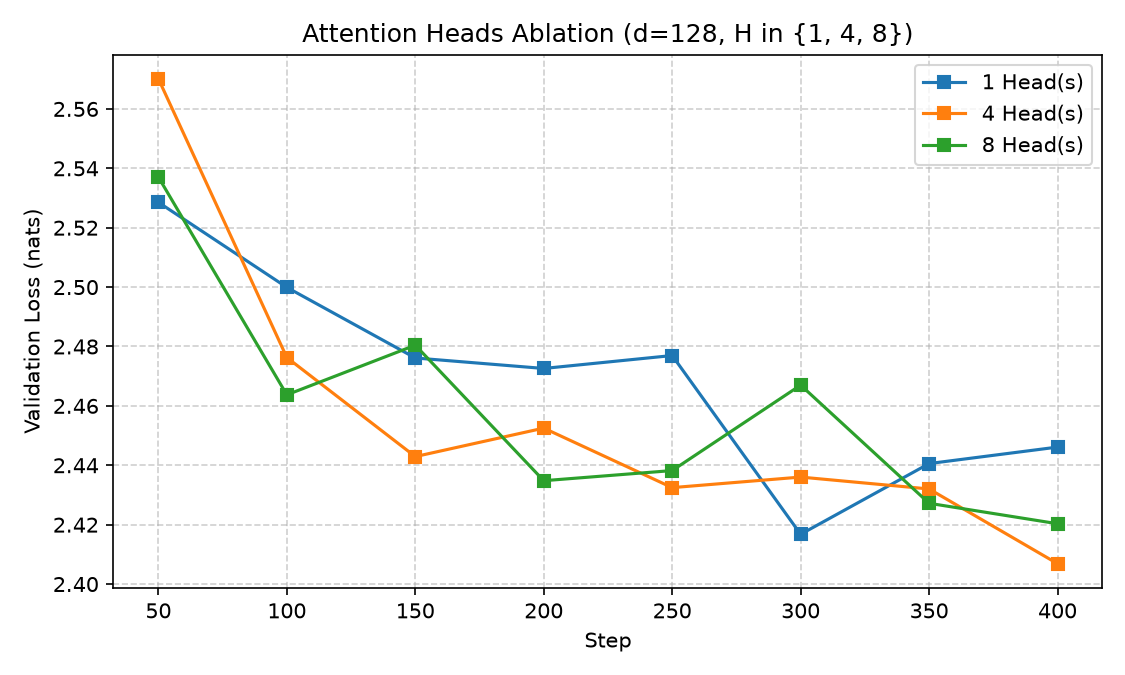

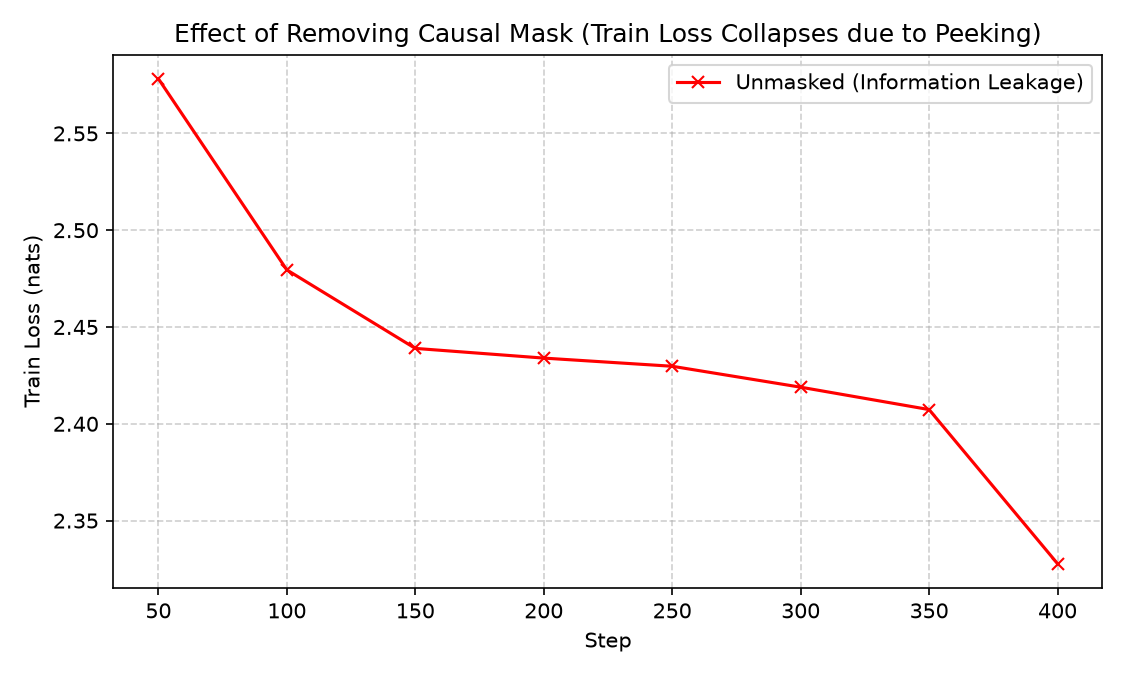

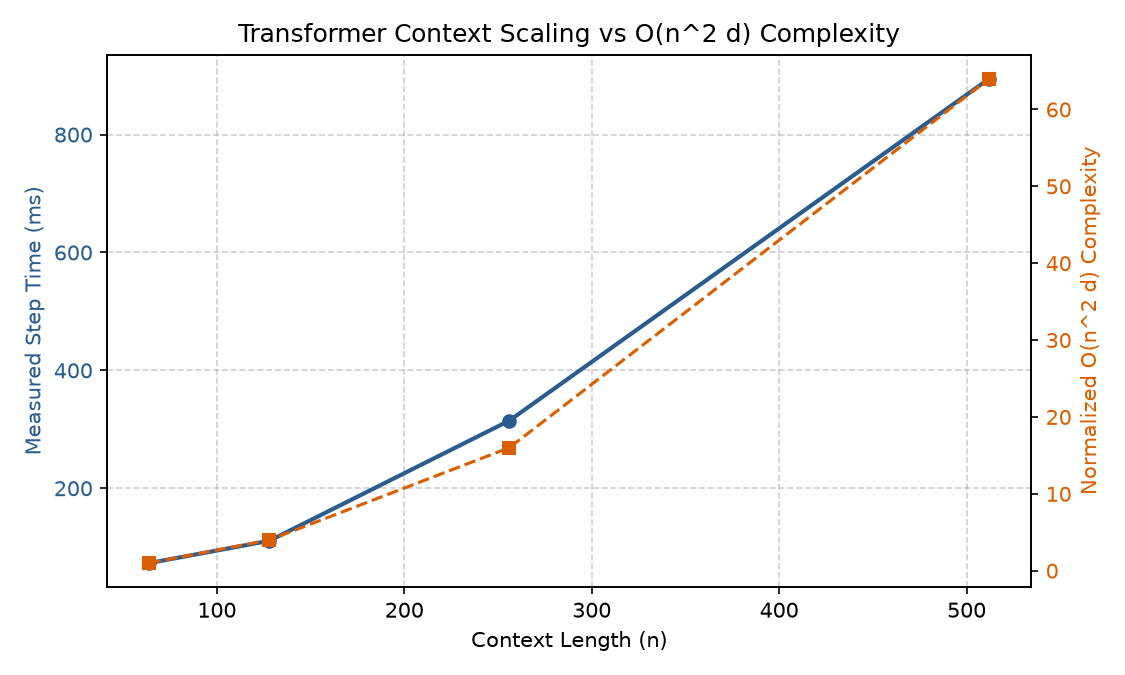

In [7]:
# Experiments: Task 5 Ablations (Heatmaps, Heads, Causal Mask, Context Scaling)
from test_p2_pipeline import (
    run_p2_task_5a_heatmaps,
    run_p2_task_5b_heads_ablation,
    run_p2_task_5c_no_mask_ablation,
    run_p2_task_5d_context_scaling
)

run_p2_task_5a_heatmaps(model_lm, ch2idx, idx2ch)
run_p2_task_5b_heads_ablation(tr_data, v_data, v_size)
run_p2_task_5c_no_mask_ablation(tr_data, v_data, v_size, ch2idx, idx2ch)
run_p2_task_5d_context_scaling(v_size)